# Les fortes baisses de prix s'accompagnent-elles d'un volume d'échanges plus élevé que les fortes hausses ?

*Projet Python pour la data science – Groupe 4*

## 0. Configuration

Le notebook importe les modules Python de `Projet/` et lit un fichier CSV par action dans `data/raw/`. Si les neuf fichiers sont présents, aucune clé API n’est nécessaire. Si le dossier est vide, il faut renseigner `TWELVEDATA_API_KEY` dans le fichier local `.env` pour télécharger les données depuis Twelve Data.

Les bibliothèques utilisées sont pandas, NumPy, SciPy, Matplotlib, seaborn (version 0.13 ou ultérieure), requests et python-dotenv.

In [21]:
import sys
from pathlib import Path

sys.path.insert(0, "Projet")   # les modules du projet sont dans le dossier Projet/

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import collect
import clean
import features
import Analysis as an
import Plots
from collect import TICKERS, START_DATE, END_DATE

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 160)

## 1. Problématique et contexte

### 1.1 Question et intérêt

Lorsqu'une action chute fortement, les échanges sont en général plus nombreux que lorsqu'elle progresse autant. Cette observation est ancienne, et la littérature sur le lien entre prix et volume la documente depuis plusieurs décennies. Karpoff (1987) propose une synthèse de référence : le volume tend à augmenter avec l'ampleur des variations de cours, quel que soit leur sens. La question du **signe** du mouvement est plus ouverte. Certaines études trouvent un volume plus élevé lors des hausses, d'autres lors des baisses, et les résultats dépendent du marché, de la période et de la mesure du volume.

À travers ce projet, nous cherchons à savoir si :
> À ampleur égale, les fortes baisses de cours sont-elles associées à un volume d'échanges plus élevé que les fortes hausses ?

Cette question est intéressante pour trois raisons. D'abord, elle sépare deux effets que les études confondent souvent, l'ampleur du mouvement et son sens. Ensuite, elle est liée à des idées économiques concrètes : une baisse forte peut signaler une information nouvelle et inquiétante, ou provoquer des ventes forcées, et ces deux mécanismes laissent des traces différentes dans le volume. Enfin, la réponse a des usages pratiques.


### 1.2 Choix de l'échantillon

Nous étudions neuf grandes entreprises cotées aux États-Unis : AAPL, MSFT, GOOGL, AMZN, NVDA, JPM, NFLX, SBUX et TTE. Ce choix repose sur quatre critères :

- **la liquidité** : ces titres sont parmi les plus échangés au monde, ce qui limite les effets de carnet d'ordres peu profond ;
- **la disponibilité des données** : les cours et volumes sont complets sur toute la période, sans interruption ;
- **la diversité sectorielle** : technologie, finance, distribution, streaming, restauration et énergie sont représentés, ce qui réduit le risque que le résultat reflète un seul secteur ;
- **la faisabilité** : neuf actions couvrent la question tout en tenant dans le quota gratuit de l'API, et permettent de présenter des résultats lisibles.

TTE est une société française, cotée à New York sous forme d'ADR. Son volume américain ne représente qu'une part de ses échanges totaux. Nous la conservons pour la diversité, avec cette réserve explicite. Un échantillon plus large serait préférable pour généraliser, mais il rendrait les figures et l'interprétation plus difficiles à suivre, et il augmenterait encore le nombre de comparaisons multiples.



## 2. Données

Après avoir recherché une source proposant des données boursières historiques quotidiennes, nous avons retenu Twelve Data pour son API et la disponibilité des cours et volumes des actions étudiées. Nous avons vérifié la couverture de la période, la cohérence des données ainsi que les conditions d'utilisation de l'API.

La collecte est automatisée avec Python. Chaque observation correspond à une action pour une journée de cotation et comprend les cours d'ouverture, de clôture, le plus haut et le plus bas de la séance, ainsi que le volume échangé. Nous utilisons des cours ajustés des divisions d'actions et des versements de dividendes afin de tenir compte de ces opérations dans l'évolution historique des prix. Le cours de clôture ajusté sert au calcul des rendements journaliers, tandis que le volume permet de mesurer l'intensité de l'activité sur le marché. Enfin, des contrôles portant sur les doublons, les valeurs manquantes et la couverture temporelle permettent de vérifier la qualité des données avant leur analyse.

### 2.1 Chargement des données brutes

In [22]:
# Collecte : collect.main() télécharge les données Twelve Data directement dans data/raw/
# (les fichiers déjà présents sont ignorés). Nécessite TWELVEDATA_API_KEY dans le fichier .env.
if not list(Path("data/raw").glob("*.csv")):
    collect.main()

raw = clean.load_all()
print(raw.shape)
raw.head()

(11862, 7)


,datetime,open,high,low,close,volume,ticker
0,2020-10-01,113.90,113.98,112.15,113.08,116120400,AAPL
1,2020-10-02,109.30,111.70,108.65,109.43,144712000,AAPL
2,2020-10-05,110.29,112.94,109.94,112.80,106243800,AAPL
3,2020-10-06,112.02,112.43,108.68,109.56,161498200,AAPL
4,2020-10-07,110.98,111.88,110.50,111.42,96849000,AAPL


In [23]:
raw.dtypes

datetime        str
open        float64
high        float64
low         float64
close       float64
volume        int64
ticker          str
dtype: object

### 2.2 Contrôles avant nettoyage (doublons, valeurs manquantes)

Nous attendons une seule ligne par action et par date. Un doublon donnerait trop de poids à une séance. Un cours de clôture manquant empêcherait de calculer le rendement du jour.

In [24]:
print("Doublons (ticker, datetime) :", raw.duplicated(subset=["ticker", "datetime"]).sum())
raw.isna().sum().to_frame("valeurs manquantes")

Doublons (ticker, datetime) : 0


,valeurs manquantes
datetime,0
open,0
high,0
low,0
close,0
volume,0
ticker,0


### 2.3 Nettoyage et journal des exclusions

In [25]:
cleaned, log = clean.clean(raw.copy())
pd.Series(log, name="lignes").to_frame()

,lignes
rows_read,11862
duplicates_removed,0
missing_removed,0
invalid_removed,0
rows_kept,11862


Nous avons collecté 11862 observations. Les données étant quotidiennes, elles couvrent uniquement les jours de cotation, les week-ends et jours fériés boursiers étant naturellement exclus. Nous vérifions que les cours de clôture et les volumes sont positifs, et que le plus haut de la séance est supérieur ou égal au plus bas. Aucun doublon, aucune valeur manquante ni aucune observation ne présentant d'incohérence au regard de ces critères n'a été détecté. Nous conservons donc l'ensemble des 11862 observations.

### 2.4 Couverture de la période

In [26]:
coverage = cleaned.groupby("ticker")["datetime"].agg(premiere_date="min", derniere_date="max", n_jours="count")
coverage["n_jours_2021_2025"] = (cleaned[cleaned["datetime"].between(an.ANALYSIS_START, an.ANALYSIS_END)]
                                 .groupby("ticker")["datetime"].count())
print(f"Période demandée à la collecte : {START_DATE} -> {END_DATE}")
coverage

Période demandée à la collecte : 2020-10-01 -> 2025-12-31


,premiere_date,derniere_date,n_jours,n_jours_2021_2025
ticker,,,,
AAPL,2020-10-01,2025-12-30,1318,1254
AMZN,2020-10-01,2025-12-30,1318,1254
GOOGL,2020-10-01,2025-12-30,1318,1254
JPM,2020-10-01,2025-12-30,1318,1254
MSFT,2020-10-01,2025-12-30,1318,1254
NFLX,2020-10-01,2025-12-30,1318,1254
NVDA,2020-10-01,2025-12-30,1318,1254
SBUX,2020-10-01,2025-12-30,1318,1254
TTE,2020-10-01,2025-12-30,1318,1254


In [27]:
clean.check_coverage(cleaned)

              min        max  count
ticker                             
AAPL   2020-10-01 2025-12-30   1318
AMZN   2020-10-01 2025-12-30   1318
GOOGL  2020-10-01 2025-12-30   1318
JPM    2020-10-01 2025-12-30   1318
MSFT   2020-10-01 2025-12-30   1318
NFLX   2020-10-01 2025-12-30   1318
NVDA   2020-10-01 2025-12-30   1318
SBUX   2020-10-01 2025-12-30   1318
TTE    2020-10-01 2025-12-30   1318


Chaque action compte 1 318 séances, dont 1 254 sur la période d’étude. Les derniers mois de 2020 servent à calculer le volume habituel dès le début de 2021. La dernière séance présente dans les fichiers est celle du 30 décembre 2025, un jour avant la date de fin demandée.

## 3. Construction des variables

Nous calculons le rendement logarithmique quotidien avec la formule $\ln(C_t/C_{t-1})$, où $C_t$ est le cours de clôture du jour et $C_{t-1}$ celui de la séance précédente. Nous classons la séance en « forte baisse » si ce rendement est inférieur ou égal à −2 %, et en « forte hausse » s’il est supérieur ou égal à +2 %. Les autres séances forment une troisième catégorie.

Pour obtenir le **volume relatif**, nous divisons le volume du jour par le volume médian des 60 séances précédentes de la même action. Un volume relatif de 1,20 signifie qu’il s’est échangé 20 % de titres de plus que d’habitude. Nous excluons la séance en cours du calcul de la médiane pour éviter qu’une journée très active influence sa propre référence.

In [28]:
feat = features.add_features(cleaned)
features.check_no_look_ahead(feat)
feat[["ticker", "datetime", "close", "volume", "log_return", "baseline",
      "rel_volume", "large_drop", "large_rise"]].dropna().head()

Look-ahead check passed.


,ticker,datetime,close,volume,log_return,baseline,rel_volume,large_drop,large_rise
60,AAPL,2020-12-28,132.57,124486200,0.04,"109,737,550.00",1.13,False,True
61,AAPL,2020-12-29,130.81,121047300,-0.01,"109,737,550.00",1.10,False,False
62,AAPL,2020-12-30,129.69,96452100,-0.01,"109,737,550.00",0.88,False,False
63,AAPL,2020-12-31,128.70,99116600,-0.01,"109,737,550.00",0.90,False,False
64,AAPL,2021-01-04,125.51,143301900,-0.03,"105,393,350.00",1.36,True,False


In [29]:
df = an.prepare_analysis_data(feat)
print(df.shape, "| période :", df["datetime"].min().date(), "->", df["datetime"].max().date())
df[["ticker", "datetime", "year", "log_return", "rel_volume", "move_type", "magnitude_bin"]].head()

(11286, 16) | période : 2021-01-04 -> 2025-12-30


,ticker,datetime,year,log_return,rel_volume,move_type,magnitude_bin
0,AAPL,2021-01-04,2021,-0.03,1.36,drop,2–3 %
1,AAPL,2021-01-05,2021,0.01,0.89,other,NaN
2,AAPL,2021-01-06,2021,-0.03,1.41,drop,3–4 %
3,AAPL,2021-01-07,2021,0.03,0.98,rise,3–4 %
4,AAPL,2021-01-08,2021,0.01,0.95,other,NaN


In [30]:
# Nombre de jours par type de mouvement et par action
pd.crosstab(df["ticker"], df["move_type"])

move_type,drop,other,rise
ticker,,,
AAPL,123,1008,123
AMZN,167,909,178
GOOGL,140,957,157
JPM,85,1084,85
MSFT,114,1023,117
NFLX,180,883,191
NVDA,267,663,324
SBUX,112,1027,115
TTE,116,1022,116


In [31]:
# Distribution du volume relatif (tous jours confondus)
df.groupby("ticker")["rel_volume"].describe()

,count,mean,std,min,25%,50%,75%,max
ticker,,,,,,,,
AAPL,"1,254.00",1.08,0.42,0.40,0.83,0.98,1.18,6.53
AMZN,"1,254.00",1.09,0.46,0.26,0.81,0.98,1.21,4.33
GOOGL,"1,254.00",1.13,0.48,0.32,0.84,1.00,1.25,4.13
JPM,"1,254.00",1.10,0.49,0.27,0.82,0.98,1.20,4.65
MSFT,"1,254.00",1.09,0.40,0.26,0.83,0.99,1.22,3.44
NFLX,"1,254.00",1.26,1.23,0.31,0.78,1.00,1.34,23.89
NVDA,"1,254.00",1.09,0.43,0.30,0.83,0.98,1.22,4.76
SBUX,"1,254.00",1.16,0.70,0.31,0.84,1.02,1.28,14.62
TTE,"1,254.00",1.09,0.49,0.21,0.75,0.97,1.29,4.88


L’échantillon final contient 11 286 observations. Sur le même nombre de séances, Nvidia connaît 591 fortes variations, contre 170 pour JPMorgan. Pour chaque action, le volume relatif médian sur l’ensemble des séances est proche de 1. Certaines journées se distinguent toutefois. Chez Netflix, le volume atteint presque 24 fois son niveau habituel lors de la séance la plus active en volume relatif.

## 4. Analyse descriptive

Pour chaque action, nous comparons le volume relatif médian des deux groupes. La médiane représente une séance typique, même si quelques journées ont un volume exceptionnel. Pour exprimer l’écart en pourcentage, nous prenons comme référence la médiane des jours de forte hausse.

In [32]:
summary = an.summary_table(df)
summary[["n_drop", "n_rise", "median_relvol_drop", "median_relvol_rise",
         "diff_relvol", "diff_relvol_pct"]]

,n_drop,n_rise,median_relvol_drop,median_relvol_rise,diff_relvol,diff_relvol_pct
ticker,,,,,,
AAPL,123,123,1.21,1.18,0.03,2.85
MSFT,114,117,1.39,1.17,0.22,18.68
GOOGL,140,157,1.27,1.19,0.08,6.44
AMZN,167,178,1.21,1.17,0.04,3.76
NVDA,267,324,1.11,1.09,0.02,1.69
JPM,85,85,1.36,1.26,0.10,7.96
TTE,116,116,1.22,1.02,0.20,19.44
NFLX,180,191,1.23,1.32,-0.09,-6.64
SBUX,112,115,1.36,1.30,0.06,4.83


In [33]:
# Volumes bruts (nombre de titres échangés)
summary[["mean_vol_drop", "median_vol_drop", "mean_vol_rise", "median_vol_rise",
         "diff_rawvol_pct"]].round(0)

,mean_vol_drop,median_vol_drop,mean_vol_rise,median_vol_rise,diff_rawvol_pct
ticker,,,,,
AAPL,"93,770,381.00","90,009,200.00","94,274,104.00","90,131,400.00",-0.00
MSFT,"35,493,160.00","34,592,200.00","33,495,123.00","30,338,000.00",14.00
GOOGL,"43,636,840.00","39,644,000.00","42,382,567.00","37,184,000.00",7.00
AMZN,"77,820,365.00","70,343,300.00","72,361,875.00","65,232,950.00",8.00
NVDA,"466,293,452.00","453,795,000.00","447,019,729.00","432,916,500.00",5.00
JPM,"17,620,712.00","15,055,400.00","15,385,032.00","13,548,600.00",11.00
TTE,"2,365,857.00","2,238,200.00","2,252,277.00","2,060,600.00",9.00
NFLX,"87,951,654.00","57,110,500.00","89,523,094.00","65,202,000.00",-12.00
SBUX,"12,672,375.00","10,691,150.00","13,009,074.00","9,828,400.00",9.00


Pour Apple, le volume brut médian est proche de 90 millions de titres dans les deux groupes. Quand on tient compte du volume habituel de l’action, le volume relatif médian est supérieur de 2,85 % les jours de forte baisse. Cette mesure permet aussi de comparer des actions dont les volumes habituels sont très différents.

## 5. Visualisations

### 5.1 Volume relatif médian : baisses vs hausses

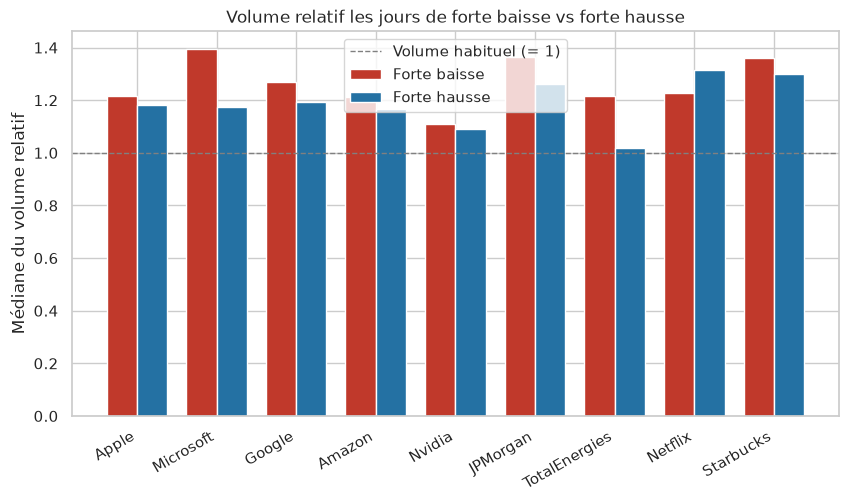

In [34]:
fig = Plots.plot_group_bar(summary, save_as="01_barres_groupees")
plt.show()

Pour Microsoft, le volume relatif médian atteint 1,39 les jours de forte baisse et 1,17 les jours de forte hausse. Dans les deux cas, on échange davantage de titres que d’habitude. Netflix est la seule action pour laquelle l’ordre s’inverse, avec une médiane de 1,23 lors des baisses et de 1,32 lors des hausses.

### 5.2 Distribution du volume relatif

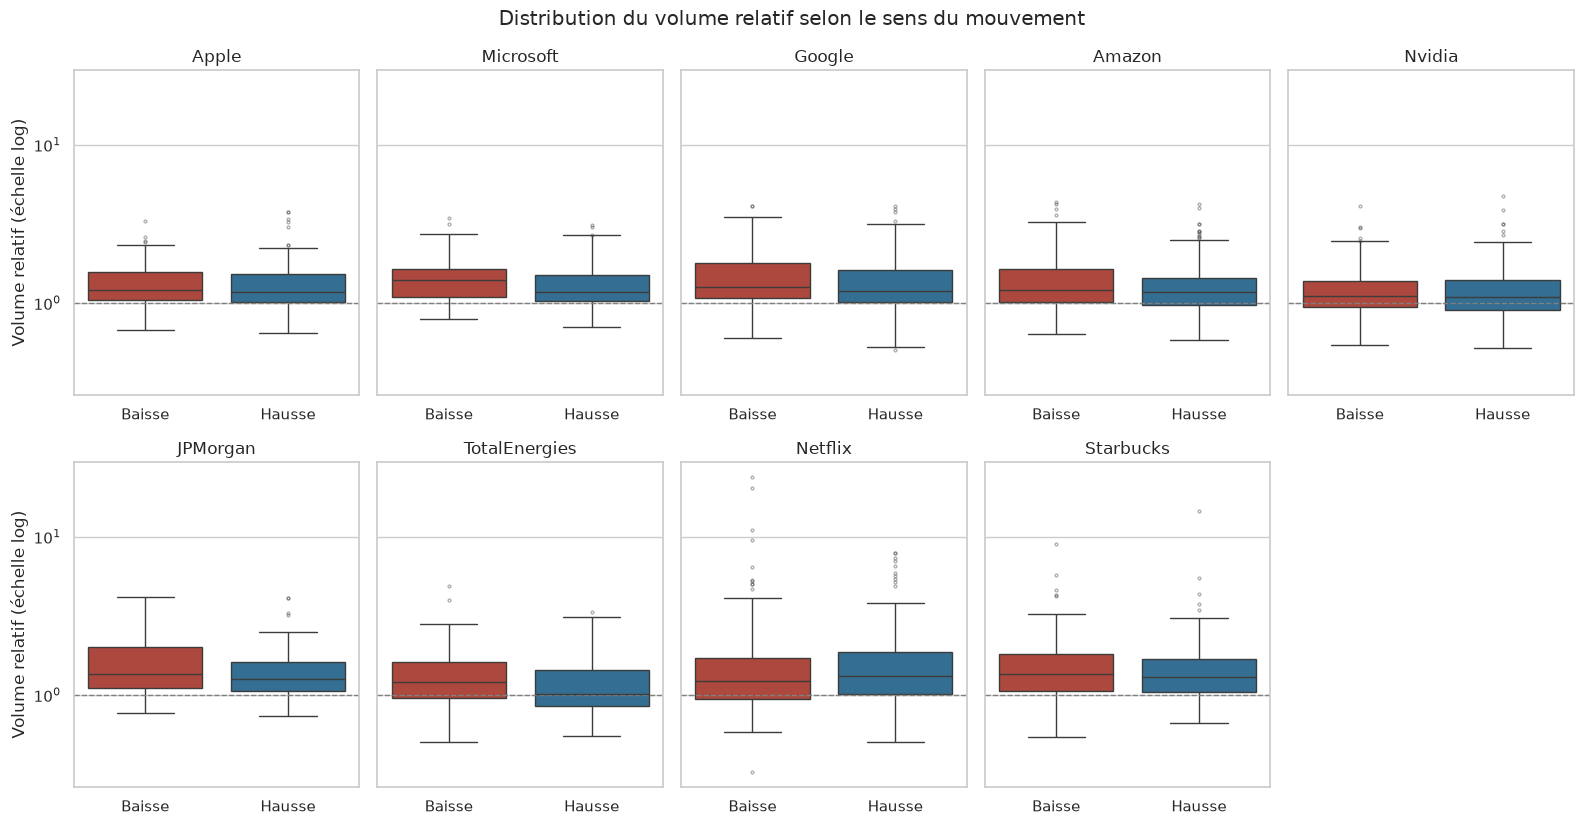

In [35]:
fig = Plots.plot_boxplots(df, save_as="02_boxplots")
plt.show()

Le trait dans chaque boîte indique la médiane. La boîte contient la moitié centrale des observations. Pour plusieurs actions, surtout Apple et Nvidia, les deux boîtes se recouvrent largement. Même lorsque la médiane est plus élevée les jours de baisse, de nombreux jours de hausse présentent des volumes comparables. L’échelle logarithmique permet de voir aussi les journées de très fort volume.

### 5.3 Évolution par année

ticker,AAPL,MSFT,GOOGL,AMZN,NVDA,JPM,TTE,NFLX,SBUX
year,,,,,,,,,
2021,0.18,0.17,-0.12,0.08,-0.21,0.34,0.06,-0.05,0.83
2022,0.06,0.15,0.10,0.04,-0.05,-0.09,0.34,-0.20,0.07
2023,0.11,-0.07,-0.12,-0.14,-0.05,-0.54,-0.09,-0.32,0.06
2024,-0.04,0.51,0.57,0.15,0.09,0.32,0.03,0.00,-0.14
2025,-0.10,0.53,0.31,0.13,0.21,0.40,0.15,0.05,0.11


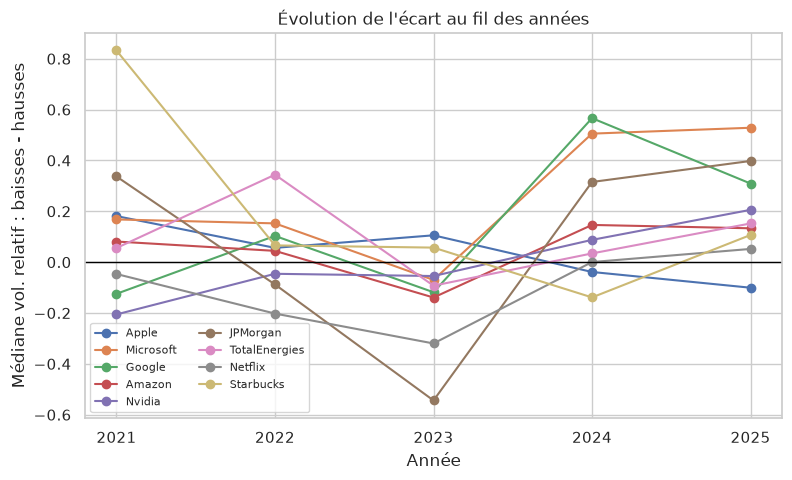

In [36]:
yearly = an.yearly_diff(df)
display(yearly)
fig = Plots.plot_yearly_lines(yearly, save_as="03_evolution_annuelle")
plt.show()

Une valeur positive indique que le volume relatif médian est plus élevé les jours de forte baisse cette année-là. Pour JPMorgan, l’écart passe de −0,54 en 2023 à +0,32 en 2024. Sur l’ensemble de la période, l’écart est positif, alors qu’en 2023 les échanges étaient plus importants lors des fortes hausses.

### 5.4 Selon l'ampleur du mouvement et l'entreprise

magnitude_bin,2–3 %,3–4 %,> 4 %
ticker,,,
AAPL,0.06,0.10,-0.25
MSFT,0.26,0.09,-0.19
GOOGL,0.05,0.30,-0.16
AMZN,0.01,0.03,-0.06
NVDA,0.06,-0.02,0.02
JPM,0.03,0.24,0.51
TTE,0.11,0.52,0.34
NFLX,-0.03,-0.09,-0.41
SBUX,-0.05,0.03,-0.06


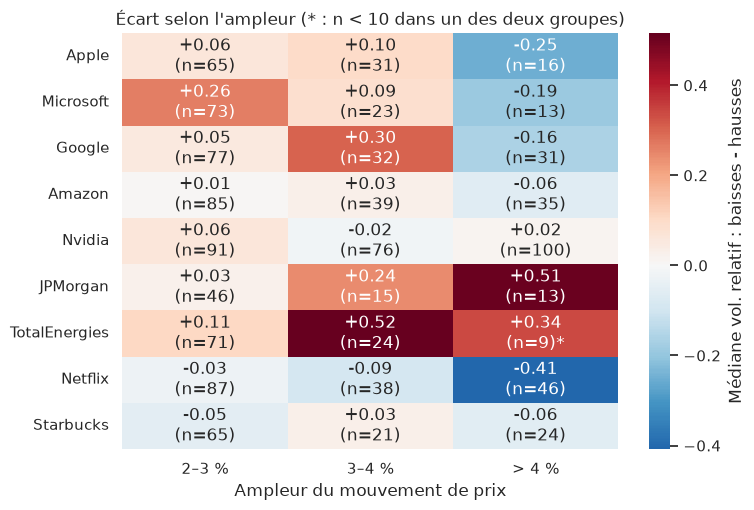

In [37]:
diff, nmin = an.heatmap_tables(df)
display(diff)
fig = Plots.plot_heatmap(diff, nmin, save_as="04_heatmap")
plt.show()

Chaque case compare les baisses et les hausses d’une même tranche. Pour Apple, l’écart est positif dans les deux tranches entre 2 % et 4 %. À partir de 4 %, il devient négatif (−0,25). Les effectifs aident à interpréter les couleurs. Pour TotalEnergies, dans la tranche de 4 % ou plus, le plus petit des deux groupes ne compte que neuf séances. Quelques observations peuvent donc changer la médiane.

### 5.5 Volume relatif selon le rendement signé du jour

,bin_left,bin_right,bin_mid,n,median_lrv,ci_low,ci_high
0,-0.05,-0.04,-0.05,62,0.32,0.19,0.44
1,-0.04,-0.04,-0.04,82,0.40,0.29,0.51
2,-0.04,-0.04,-0.04,134,0.26,0.21,0.37
3,-0.04,-0.03,-0.03,199,0.24,0.18,0.31
4,-0.03,-0.03,-0.03,285,0.16,0.13,0.19
5,-0.03,-0.02,-0.02,375,0.09,0.06,0.11
6,-0.02,-0.01,-0.02,582,0.06,0.03,0.09
7,-0.01,-0.01,-0.01,846,-0.01,-0.03,0.02
8,-0.01,-0.01,-0.01,1158,-0.06,-0.09,-0.04
9,-0.01,0.00,-0.00,1435,-0.14,-0.15,-0.13


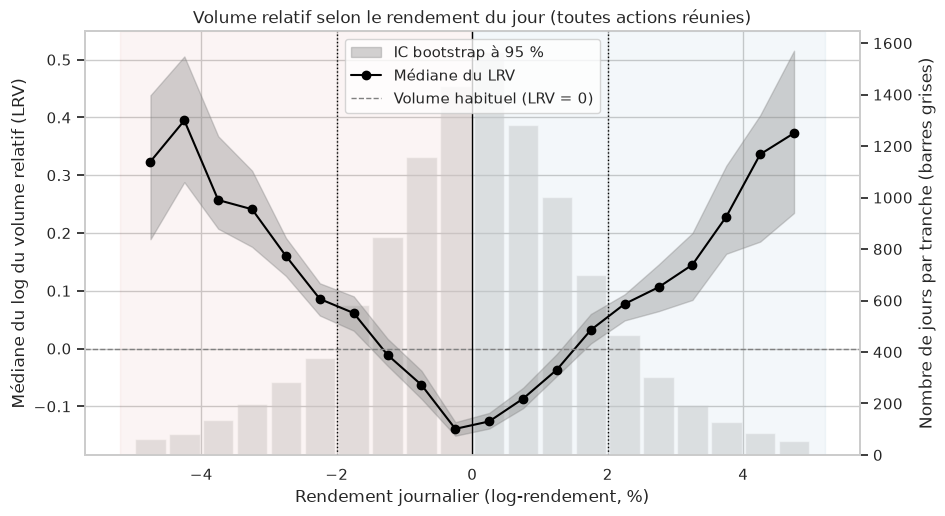

In [38]:
curve = an.signed_return_curve(df)
display(curve.round(3))
fig = Plots.plot_signed_curve(curve, save_as="05_courbe_rendement_signe")
plt.show()

Ce graphique regroupe les neuf actions, soit 10 944 observations dont le rendement logarithmique est compris entre −5 % inclus et +5 % exclu. La courbe noire représente la médiane du logarithme du volume relatif. Sur l’axe vertical, zéro correspond au volume habituel. La courbe est au plus bas près d’un rendement nul et remonte des deux côtés. Les barres grises montrent que la plupart des observations sont proches du centre. Aux extrémités, la bande grisée est plus large, ce qui traduit une plus grande incertitude.

## 6. Tests statistiques (Mann-Whitney)

Pour chaque action, nous appliquons un test de Mann–Whitney aux volumes relatifs des jours de forte baisse et de forte hausse. Le test classe les observations des deux groupes. La dernière colonne aide à interpréter le résultat. Si on tire au hasard une séance dans chaque groupe, une valeur de 0,60 signifie que le volume relatif est plus élevé le jour de baisse dans environ 60 % des comparaisons, en comptant les égalités pour moitié.

In [39]:
an.mann_whitney_table(df)

,n_drop,n_rise,U,p_value,prob_superiority
ticker,,,,,
AAPL,123,123,"7,943.00",0.50,0.53
MSFT,114,117,"8,031.00",0.01,0.60
GOOGL,140,157,"12,177.00",0.11,0.55
AMZN,167,178,"16,028.00",0.21,0.54
NVDA,267,324,"45,825.00",0.21,0.53
JPM,85,85,"4,231.00",0.05,0.59
TTE,116,116,"8,025.00",0.01,0.60
NFLX,180,191,"15,881.00",0.20,0.46
SBUX,112,115,"6,696.00",0.61,0.52


Les différences les plus nettes concernent Microsoft et TotalEnergies. Les valeurs de p du test bilatéral sont de 0,0073 et 0,0112, et les probabilités estimées sont proches de 0,60. Pour Apple, la probabilité est de 0,53 et la valeur de p de 0,50. Pour JPMorgan, la valeur de p est de 0,0541, juste au-dessus du seuil de 0,05.

Ces seuils concernent chaque test pris séparément. Si nous tenons compte des neuf tests avec la correction de Bonferroni, le seuil devient 0,05 divisé par 9, soit environ 0,0056. Aucune action ne passe ce seuil. De plus, les volumes de deux séances proches peuvent être liés. Nous interprétons donc ces tests avec prudence.

## 7. Limites et conclusion
### 7.1 Ce que les données permettent de démontrer

Les données permettent de **décrire** le lien entre l'ampleur et le sens d'un mouvement de cours, et le volume échangé, sur neuf actions et cinq ans. Elles permettent aussi de tester si un écart observé est stable d'une action à l'autre, d'une année à l'autre et d'une tranche d'ampleur à l'autre.

En revanche, elles ne permettent pas de démontrer un effet causal, ni de généraliser au-delà de l'échantillon. Les résultats sont donc des indications, qui doivent être présentées comme telles.

### 7.2 Limites

- **Association, pas causalité.** Le volume et le rendement sont mesurés le même jour. On observe qu'ils vont ensemble, mais un événement commun, comme une annonce, peut provoquer les deux.
- **Ampleur.** La comparaison brute de la section 4 ne contrôle pas l'ampleur. Les tranches (5.4) et la courbe (5.5) répondent à cette limite, sans la supprimer complètement, car le nombre de jours dans les tranches extrêmes reste faible.
- **Dépendance entre observations.** Lors d'une crise, toutes les actions chutent avec un volume élevé. Les jours ne sont donc pas indépendants, et les intervalles de confiance sont probablement trop étroits.
- **Événements.** Les résultats trimestriels, les échéances d'options de fin de trimestre et les rééquilibrages d'indices gonflent le volume dans les deux sens. Ils ne sont pas retirés de l'analyse principale.
- **Taille de l'échantillon.** Neuf actions, toutes de grande capitalisation, ne permettent pas de généraliser aux petites entreprises ni à d'autres marchés. Chaque action et chaque année contient peu de jours extrêmes, ce qui rend les résultats par cellule fragiles.
- **Tests multiples.** Avec neuf actions, trois tranches et plusieurs années, on effectue de nombreuses comparaisons. Certains écarts apparaissent par hasard. Nous n'affirmons donc aucun résultat à partir d'une seule cellule.
- **Période.** 2021–2025 inclut une baisse générale des marchés en 2022 et une forte hausse de certaines valeurs technologiques. Le résultat dépend peut-être de cette période.

### 7.3 Conclusion

Les fortes baisses sont associées à un volume relatif médian plus élevé que les fortes hausses dans huit actions sur neuf. Les écarts restent modestes, à l'exception de MSFT et TTE. Ils changent de signe selon l'année et selon l'ampleur du mouvement, et ils ne résistent pas à une correction pour comparaisons multiples. À ampleur égale, la courbe de volume relatif en fonction du rendement est presque symétrique.

**Réponse à la question : nos données ne permettent pas de conclure à une différence nette et robuste entre les baisses et les hausses.** Le volume semble dépendre surtout de l'ampleur d'un mouvement, beaucoup moins de son signe. Une légère tendance en faveur des baisses apparaît dans les médianes par action, mais elle doit être confirmée sur un échantillon plus large, sur d'autres périodes et avec une mesure du volume issue de plusieurs sources.